Labelled Data Shape: (4940, 42)
Unlabelled Data Shape: (3111, 41)
Except Data Shape: (4940, 42)
X_train Labelled Shape: (49, 41)
y_train Labelled Shape: (49,)
X_test Shape: (4891, 41)
y_test Shape: (4891,)
X_except Shape: (4940, 41)
y_except Shape: (4940,)


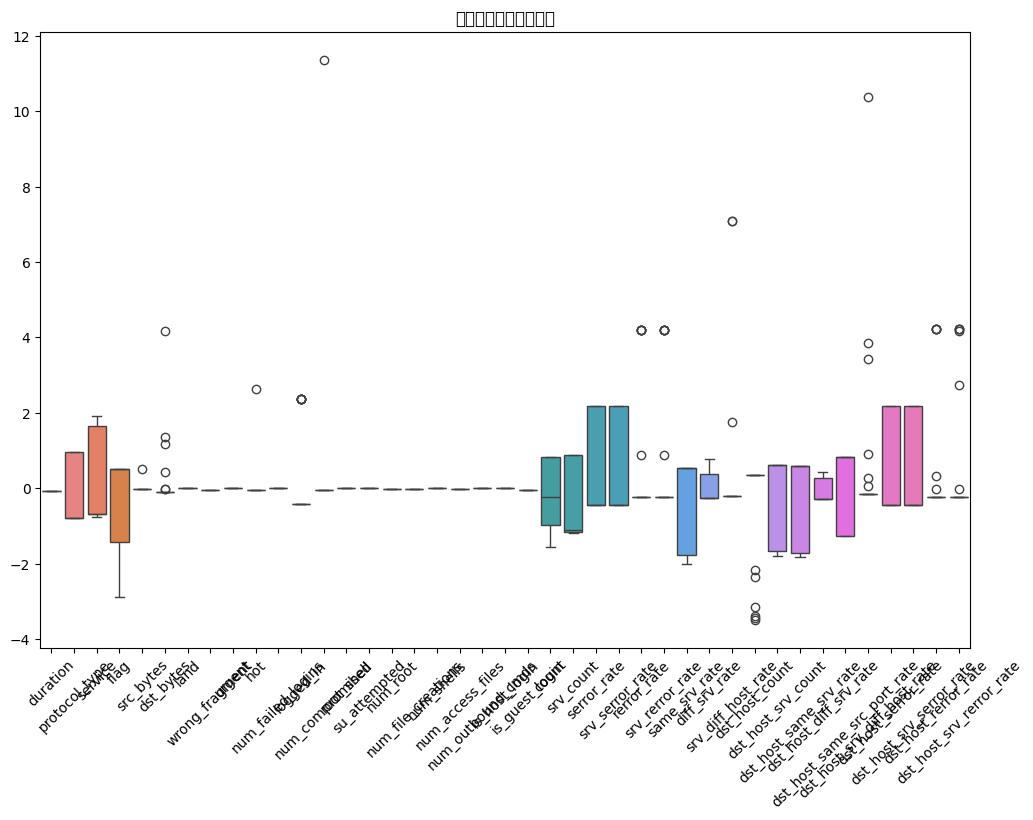

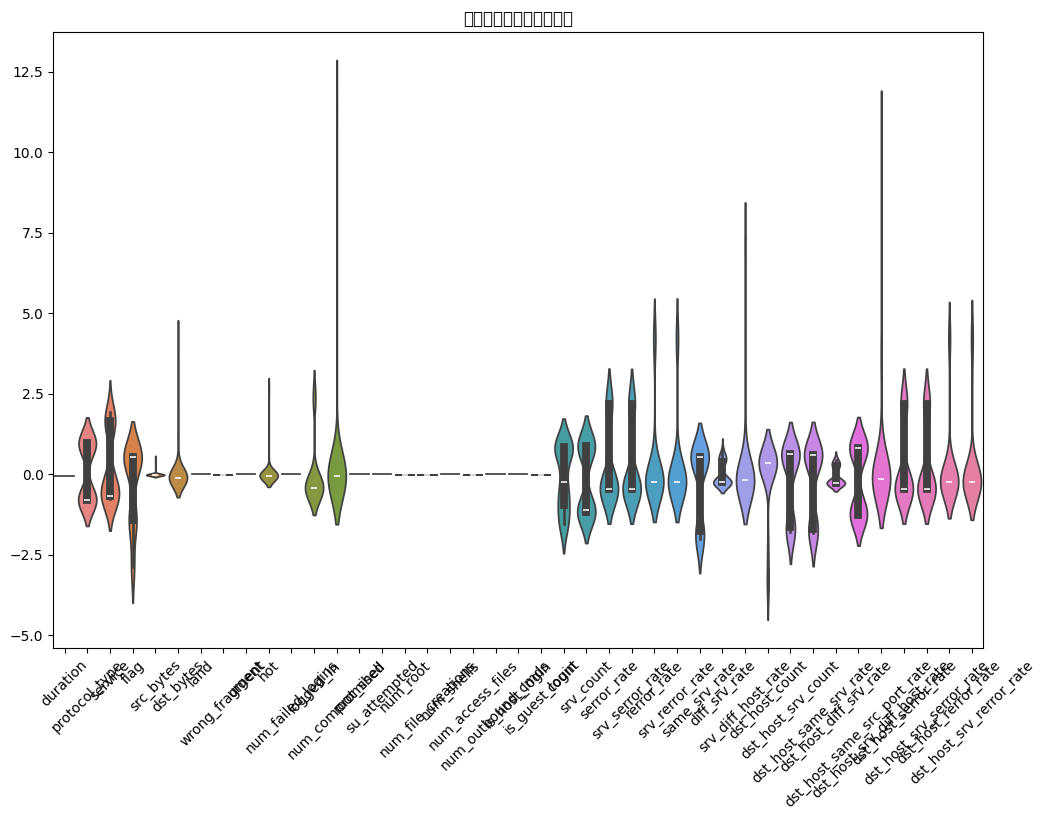

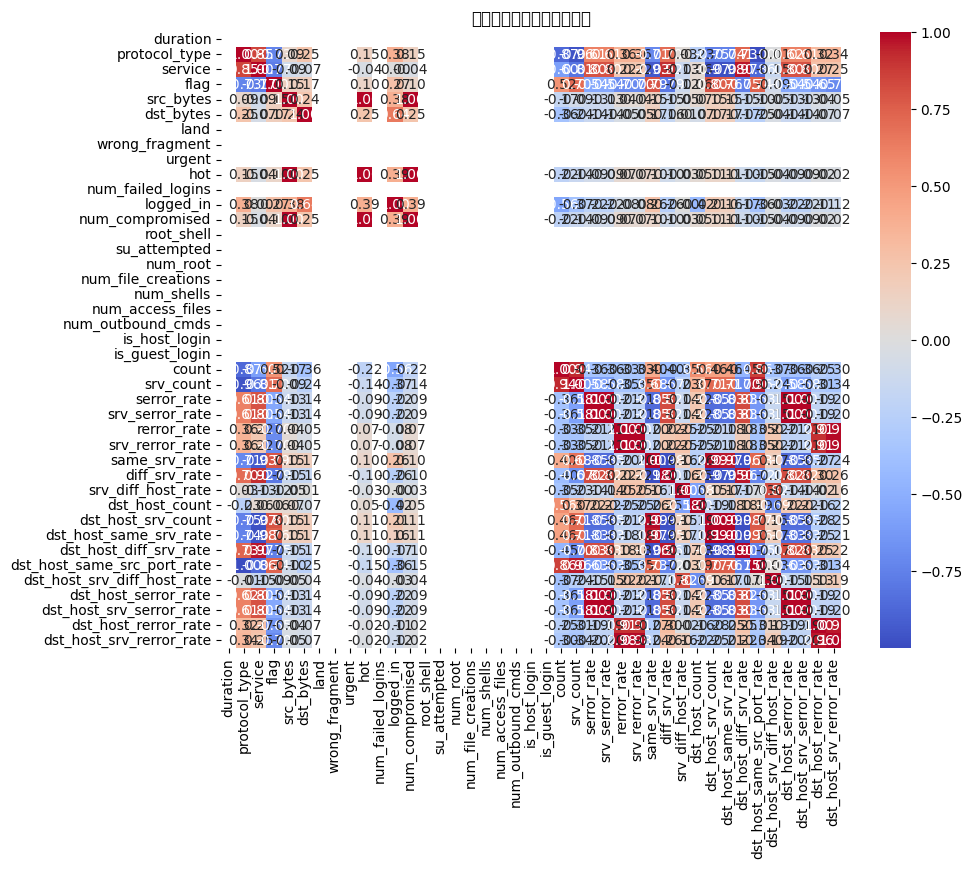

In [66]:
import pandas as pd
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt
import seaborn as sns
import warnings 

# 忽略特定的 UserWarning 警告
warnings.filterwarnings("ignore", message="Glyph .* missing from current font.")

# 替换为实际数据集路径
labelled_data_path = 'kddcup_1_percent'
unlabelled_data_path = 'kddcup_1_percent.unlabeled'
except_path = 'kddcup_1_percent'

# 读取有标签的数据集
df_labelled = pd.read_csv(labelled_data_path, header=None)

# 读取无标签的数据集
df_unlabelled = pd.read_csv(unlabelled_data_path, header=None)
df_except = pd.read_csv(except_path, header=None)

# 定义列名
columns = ["duration", "protocol_type", "service", "flag", "src_bytes", "dst_bytes", 
           "land", "wrong_fragment", "urgent", "hot", "num_failed_logins", 
           "logged_in", "num_compromised", "root_shell", "su_attempted", 
           "num_root", "num_file_creations", "num_shells", "num_access_files", 
           "num_outbound_cmds", "is_host_login", "is_guest_login", "count", 
           "srv_count", "serror_rate", "srv_serror_rate", "rerror_rate", 
           "srv_rerror_rate", "same_srv_rate", "diff_srv_rate", "srv_diff_host_rate", 
           "dst_host_count", "dst_host_srv_count", "dst_host_same_srv_rate", 
           "dst_host_diff_srv_rate", "dst_host_same_src_port_rate", 
           "dst_host_srv_diff_host_rate", "dst_host_serror_rate", 
           "dst_host_srv_serror_rate", "dst_host_rerror_rate", 
           "dst_host_srv_rerror_rate", "label"]

df_labelled.columns = columns
df_unlabelled.columns = columns[:-1]  # 无标签数据集没有label列
df_except.columns = columns

# 获取分类特征的所有种类
categorical_columns = ["protocol_type", "service", "flag"]

# 为所有分类特征创建一个LabelEncoder对象
le_dict = {col: LabelEncoder() for col in categorical_columns}

# Fit LabelEncoder对象于有标签和无标签数据集中
for col in categorical_columns:
    le = le_dict[col]
    le.fit(pd.concat([df_labelled[col], df_unlabelled[col], df_except[col]]))

# 对有标签数据集进行编码
for col in categorical_columns:
    le = le_dict[col]
    df_labelled[col] = le.transform(df_labelled[col])

# 对无标签数据集进行编码
for col in categorical_columns:
    le = le_dict[col]
    df_unlabelled[col] = le.transform(df_unlabelled[col])

# 对df_except进行编码
for col in categorical_columns:
    le = le_dict[col]
    df_except[col] = le.transform(df_except[col])

# 将标签编码
df_labelled['label'] = df_labelled['label'].apply(lambda x: 1 if x != 'normal.' else 0)
df_except['label'] = df_except['label'].apply(lambda x: 1 if x != 'normal.' else 0)

# 特征标准化
scaler = StandardScaler()
df_labelled[df_labelled.columns[:-1]] = scaler.fit_transform(df_labelled[df_labelled.columns[:-1]])
df_unlabelled[df_unlabelled.columns] = scaler.transform(df_unlabelled[df_unlabelled.columns])
df_except[df_except.columns[:-1]] = scaler.transform(df_except[df_except.columns[:-1]])

# 划分有标签数据集的训练集和测试集
X = df_labelled.drop(columns=['label'])
y = df_labelled['label']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.99, random_state=42)

# 使用训练集中所有的有标签数据
X_train_labelled = X_train
y_train_labelled = y_train

# 无标签数据
X_train_unlabelled = df_unlabelled

# 处理后的df_except
X_except = df_except.drop(columns=['label'])
y_except = df_except['label']

# 显示数据集状态
print(f"Labelled Data Shape: {df_labelled.shape}")
print(f"Unlabelled Data Shape: {df_unlabelled.shape}")
print(f"Except Data Shape: {df_except.shape}")

# 显示分割后数据集的形状
print(f"X_train Labelled Shape: {X_train_labelled.shape}")
print(f"y_train Labelled Shape: {y_train_labelled.shape}")
print(f"X_test Shape: {X_test.shape}")
print(f"y_test Shape: {y_test.shape}")
print(f"X_except Shape: {X_except.shape}")
print(f"y_except Shape: {y_except.shape}")

# 绘制箱形图
plt.figure(figsize=(12, 8))
sns.boxplot(data=X_train_labelled)
plt.title('箱形图：特征分布情况')
plt.xticks(rotation=45)
plt.show()

# 绘制小提琴图
plt.figure(figsize=(12, 8))
sns.violinplot(data=X_train_labelled)
plt.title('小提琴图：特征分布情况')
plt.xticks(rotation=45)
plt.show()

# 绘制热力图
plt.figure(figsize=(10, 8))
corr = X_train_labelled.corr()
sns.heatmap(corr, annot=True, fmt=".2f", cmap='coolwarm')
plt.title('热力图：特征之间的相关性')
plt.show()

Labelled Data Shape: (4940, 42)
Unlabelled Data Shape: (3111, 41)
Except Data Shape: (4940, 42)
X_train Labelled Shape: (49, 41)
y_train Labelled Shape: (49,)
X_test Shape: (4891, 41)
y_test Shape: (4891,)
X_except Shape: (4940, 41)
y_except Shape: (4940,)


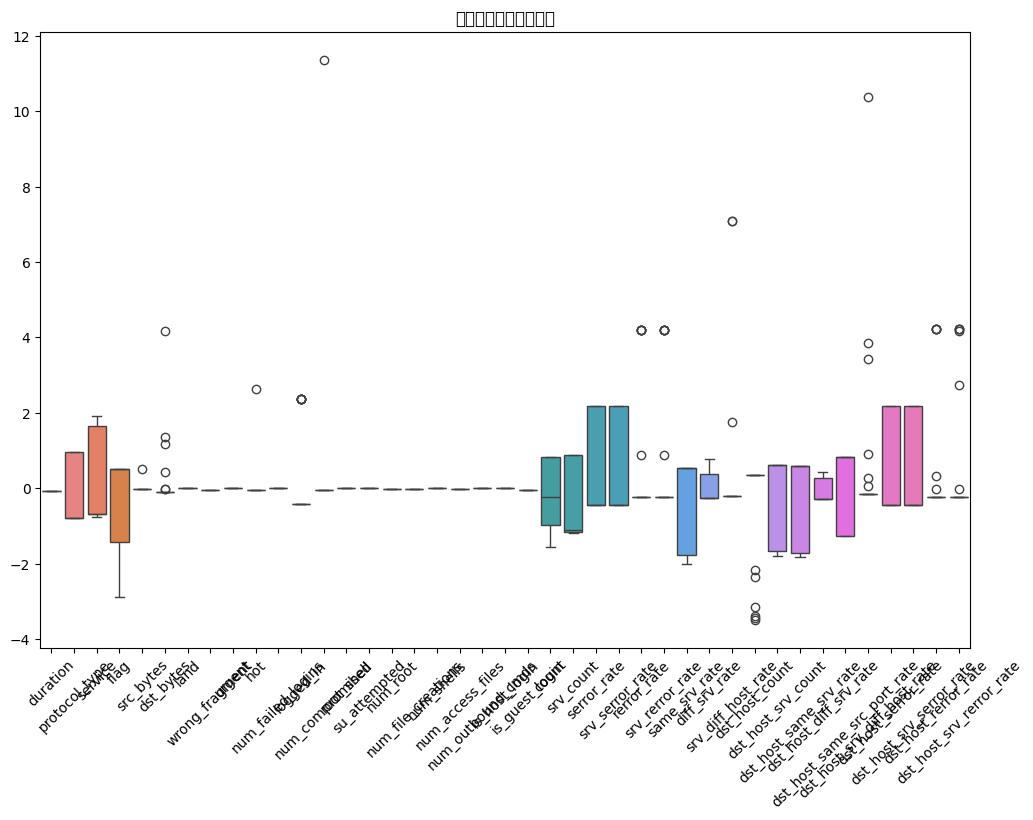

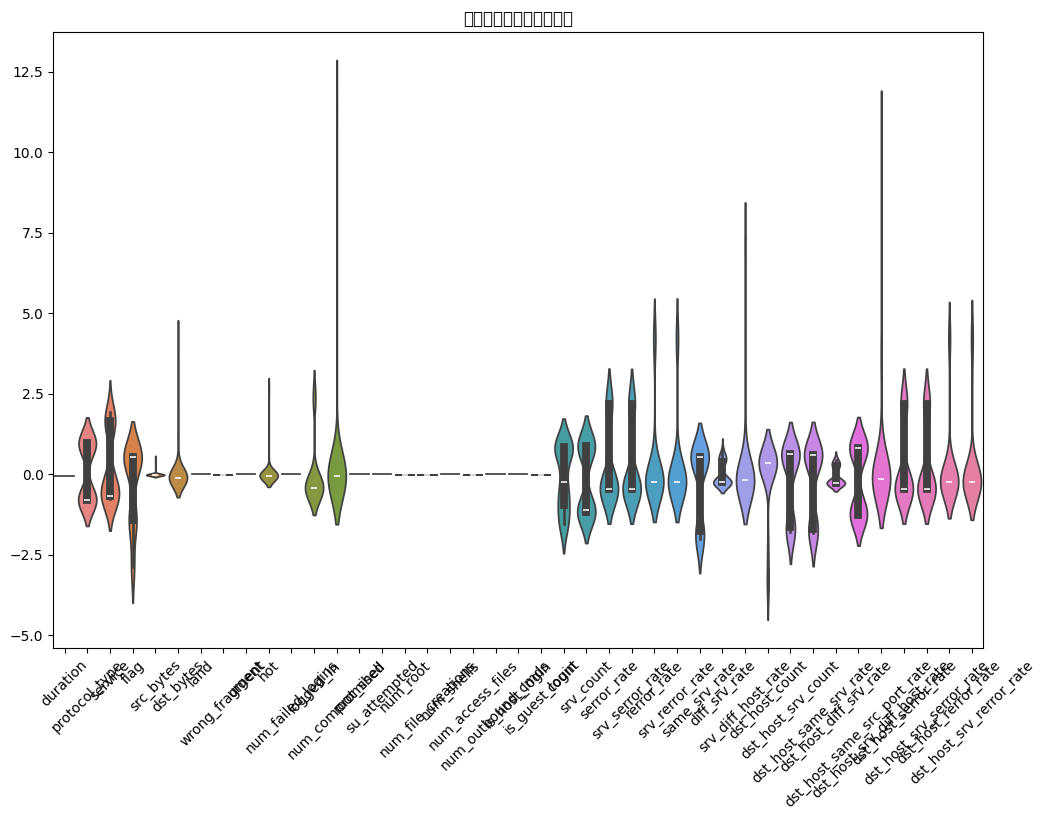

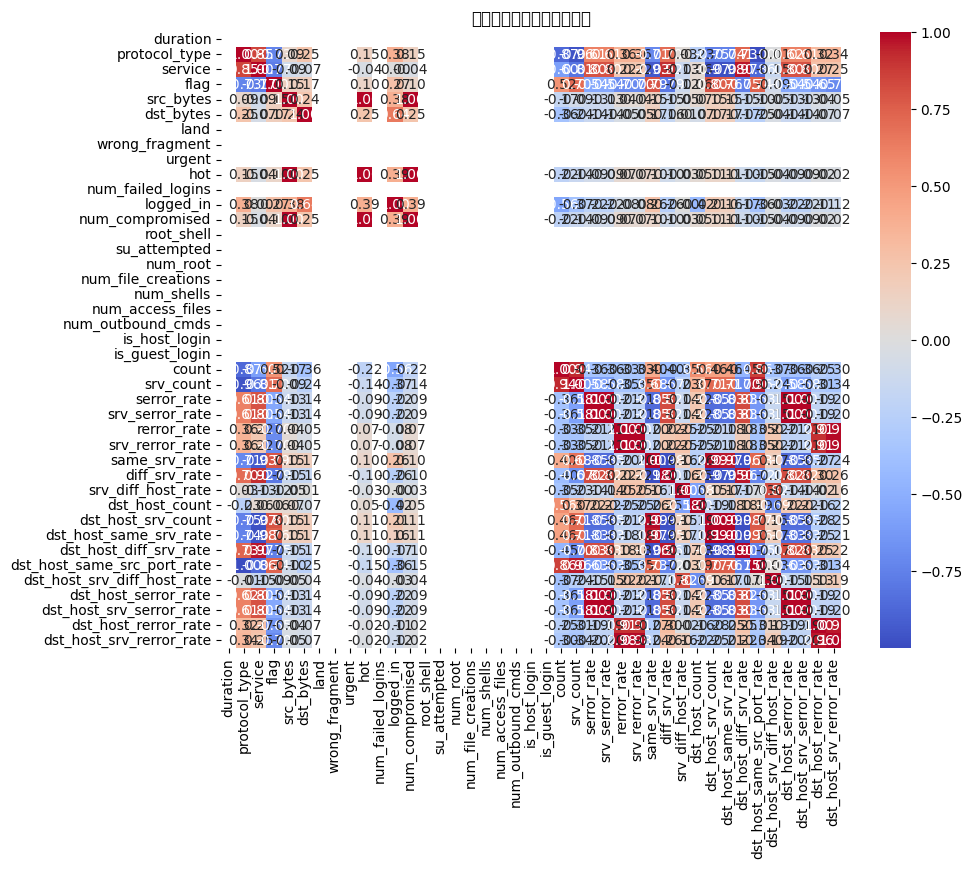

In [67]:
import pandas as pd
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt
import seaborn as sns
import warnings 
# 替换为实际数据集路径
labelled_data_path = 'kddcup_1_percent'
unlabelled_data_path = 'kddcup_1_percent.unlabeled'
except_path = 'kddcup_1_percent'

# 读取有标签的数据集
df_labelled = pd.read_csv(labelled_data_path, header=None)

# 读取无标签的数据集
df_unlabelled = pd.read_csv(unlabelled_data_path, header=None)
df_except = pd.read_csv(except_path, header=None)

# 定义列名
columns = ["duration", "protocol_type", "service", "flag", "src_bytes", "dst_bytes", 
           "land", "wrong_fragment", "urgent", "hot", "num_failed_logins", 
           "logged_in", "num_compromised", "root_shell", "su_attempted", 
           "num_root", "num_file_creations", "num_shells", "num_access_files", 
           "num_outbound_cmds", "is_host_login", "is_guest_login", "count", 
           "srv_count", "serror_rate", "srv_serror_rate", "rerror_rate", 
           "srv_rerror_rate", "same_srv_rate", "diff_srv_rate", "srv_diff_host_rate", 
           "dst_host_count", "dst_host_srv_count", "dst_host_same_srv_rate", 
           "dst_host_diff_srv_rate", "dst_host_same_src_port_rate", 
           "dst_host_srv_diff_host_rate", "dst_host_serror_rate", 
           "dst_host_srv_serror_rate", "dst_host_rerror_rate", 
           "dst_host_srv_rerror_rate", "label"]

df_labelled.columns = columns
df_unlabelled.columns = columns[:-1]  # 无标签数据集没有label列
df_except.columns = columns

# 获取分类特征的所有种类
categorical_columns = ["protocol_type", "service", "flag"]

# 为所有分类特征创建一个LabelEncoder对象
le_dict = {col: LabelEncoder() for col in categorical_columns}

# Fit LabelEncoder对象于有标签和无标签数据集中
for col in categorical_columns:
    le = le_dict[col]
    le.fit(pd.concat([df_labelled[col], df_unlabelled[col], df_except[col]]))

# 对有标签数据集进行编码
for col in categorical_columns:
    le = le_dict[col]
    df_labelled[col] = le.transform(df_labelled[col])

# 对无标签数据集进行编码
for col in categorical_columns:
    le = le_dict[col]
    df_unlabelled[col] = le.transform(df_unlabelled[col])

# 对df_except进行编码
for col in categorical_columns:
    le = le_dict[col]
    df_except[col] = le.transform(df_except[col])

# 将标签编码
df_labelled['label'] = df_labelled['label'].apply(lambda x: 1 if x != 'normal.' else 0)
df_except['label'] = df_except['label'].apply(lambda x: 1 if x != 'normal.' else 0)

# 特征标准化
scaler = StandardScaler()
df_labelled[df_labelled.columns[:-1]] = scaler.fit_transform(df_labelled[df_labelled.columns[:-1]])
df_unlabelled[df_unlabelled.columns] = scaler.transform(df_unlabelled[df_unlabelled.columns])
df_except[df_except.columns[:-1]] = scaler.transform(df_except[df_except.columns[:-1]])

# 划分有标签数据集的训练集和测试集
X = df_labelled.drop(columns=['label'])
y = df_labelled['label']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.99, random_state=42)

# 使用训练集中所有的有标签数据
X_train_labelled = X_train
y_train_labelled = y_train

# 无标签数据
X_train_unlabelled = df_unlabelled

# 处理后的df_except
X_except = df_except.drop(columns=['label'])
y_except = df_except['label']

# 显示数据集状态
print(f"Labelled Data Shape: {df_labelled.shape}")
print(f"Unlabelled Data Shape: {df_unlabelled.shape}")
print(f"Except Data Shape: {df_except.shape}")

# 显示分割后数据集的形状
print(f"X_train Labelled Shape: {X_train_labelled.shape}")
print(f"y_train Labelled Shape: {y_train_labelled.shape}")
print(f"X_test Shape: {X_test.shape}")
print(f"y_test Shape: {y_test.shape}")
print(f"X_except Shape: {X_except.shape}")
print(f"y_except Shape: {y_except.shape}")

# 绘制箱形图
plt.figure(figsize=(12, 8))
sns.boxplot(data=X_train_labelled)
plt.title('箱形图：特征分布情况')
plt.xticks(rotation=45)
plt.show()

# 绘制小提琴图
plt.figure(figsize=(12, 8))
sns.violinplot(data=X_train_labelled)
plt.title('小提琴图：特征分布情况')
plt.xticks(rotation=45)
plt.show()

# 绘制热力图
plt.figure(figsize=(10, 8))
corr = X_train_labelled.corr()
sns.heatmap(corr, annot=True, fmt=".2f", cmap='coolwarm')
plt.title('热力图：特征之间的相关性')
plt.show()

In [68]:
import numpy as np
import pandas as pd
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, classification_report

# 初始模型训练
clf = SVC(probability=True, random_state=42)
clf.fit(X_train_labelled, y_train_labelled)

# 自训练迭代
max_iterations = 10
confidence_threshold = 0.9
low_confidence_sample_size = 100  # 定义一个合理的低置信度样本数量

# 自训练（半监督学习）迭代
for iteration in range(max_iterations):
    # 半监督学习部分
    y_unlabelled_pred = clf.predict(X_train_unlabelled)
    y_unlabelled_proba = clf.predict_proba(X_train_unlabelled)
    
    # 选择高置信度样本
    high_confidence_indices = np.where(np.max(y_unlabelled_proba, axis=1) >= confidence_threshold)[0]
    
    if len(high_confidence_indices) == 0:
        break
    
    X_high_confidence = X_train_unlabelled.iloc[high_confidence_indices]
    y_high_confidence = y_unlabelled_pred[high_confidence_indices]
    
    # 将高置信度样本添加到有标签的训练集中
    X_train_labelled = pd.concat([X_train_labelled, X_high_confidence])
    y_train_labelled = pd.concat([y_train_labelled, pd.Series(y_high_confidence)])
    
    # 从无标签数据集中删除高置信度样本
    X_train_unlabelled = X_train_unlabelled.drop(X_high_confidence.index)
    
    # 主动学习部分
    # 确保低置信度样本数量不超过未标记数据的大小
    if len(X_train_unlabelled) < low_confidence_sample_size:
        low_confidence_sample_size = len(X_train_unlabelled)
    
    # 重新计算未标记样本的预测概率
    y_unlabelled_proba = clf.predict_proba(X_train_unlabelled)
    
    # 选择低置信度样本进行标注
    low_confidence_indices = np.argsort(np.max(y_unlabelled_proba, axis=1))[:low_confidence_sample_size]
    X_low_confidence = X_train_unlabelled.iloc[low_confidence_indices]
    
    # 从df_except中获取标签
    X_low_confidence_features = X_low_confidence.reset_index(drop=True)
    y_low_confidence_labels = df_except[df_except.drop(columns=['label']).apply(tuple, axis=1).isin(X_low_confidence_features.apply(tuple, axis=1))]['label'].values
    
    # 检查是否找到了所有低置信度样本的标签
    if len(y_low_confidence_labels) < low_confidence_sample_size:
        print(f"Warning: Only found {len(y_low_confidence_labels)} labels for low confidence samples.")
        low_confidence_sample_size = len(y_low_confidence_labels)
        X_low_confidence = X_low_confidence.iloc[:low_confidence_sample_size]
    
    # 添加低置信度样本及其标签到训练集中
    X_train_labelled = pd.concat([X_train_labelled, X_low_confidence])
    y_train_labelled = pd.concat([y_train_labelled, pd.Series(y_low_confidence_labels)])
    
    # 从无标签数据集中删除低置信度样本
    X_train_unlabelled = X_train_unlabelled.drop(X_low_confidence.index)
    
    # 重新训练模型
    clf.fit(X_train_labelled, y_train_labelled)

# 模型评估
y_pred = clf.predict(X_test)
print("Accuracy:", accuracy_score(y_test, y_pred))
print("Classification Report:")
print(classification_report(y_test, y_pred))


Accuracy: 0.9897771416888161
Classification Report:
              precision    recall  f1-score   support

           0       0.95      1.00      0.97       960
           1       1.00      0.99      0.99      3931

    accuracy                           0.99      4891
   macro avg       0.98      0.99      0.98      4891
weighted avg       0.99      0.99      0.99      4891



Accuracy: 0.9895726845225925
Classification Report:
              precision    recall  f1-score   support

           0       0.95      1.00      0.97       960
           1       1.00      0.99      0.99      3931

    accuracy                           0.99      4891
   macro avg       0.98      0.99      0.98      4891
weighted avg       0.99      0.99      0.99      4891



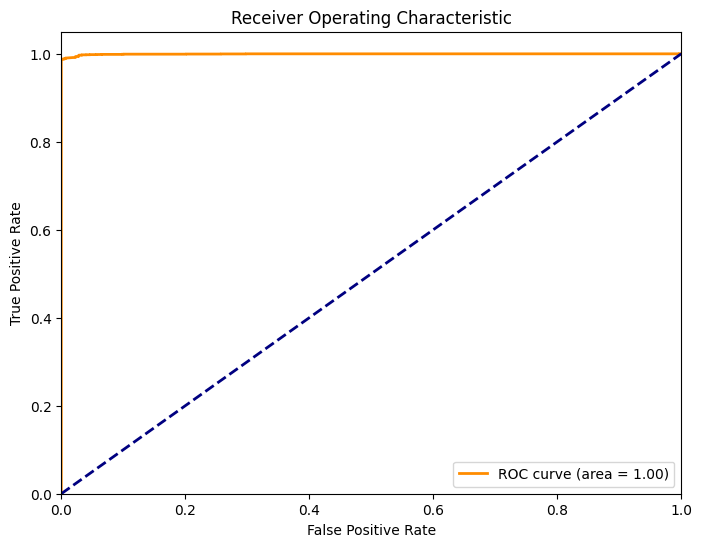

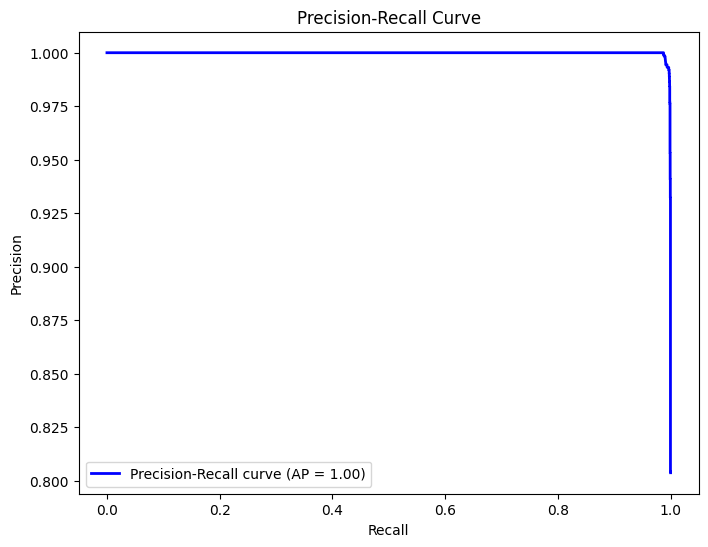

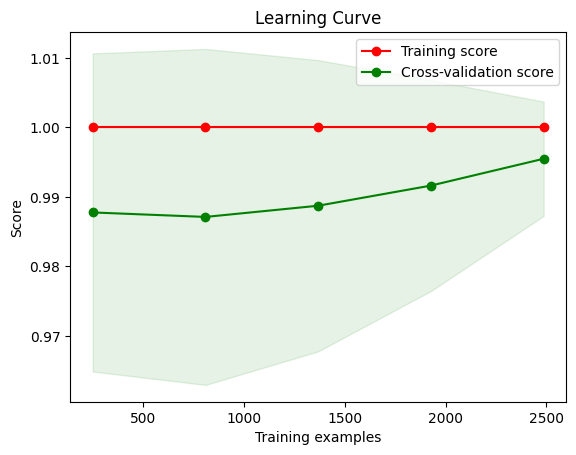

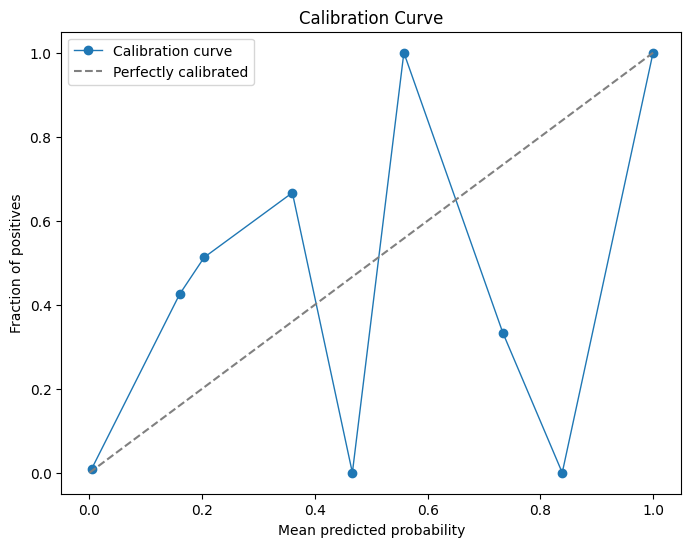

In [69]:
import numpy as np
import pandas as pd
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, classification_report, roc_curve, auc, precision_recall_curve, average_precision_score
from sklearn.model_selection import learning_curve
import matplotlib.pyplot as plt
from sklearn.calibration import calibration_curve
# import scikitplot as skplt
# 初始模型训练
clf = SVC(probability=True, random_state=42)
clf.fit(X_train_labelled, y_train_labelled)

# 自训练迭代
max_iterations = 10
confidence_threshold = 0.9
low_confidence_sample_size = 100  # 定义一个合理的低置信度样本数量

for iteration in range(max_iterations):
    # 半监督学习部分
    y_unlabelled_pred = clf.predict(X_train_unlabelled)
    y_unlabelled_proba = clf.predict_proba(X_train_unlabelled)
    
    # 选择高置信度样本
    high_confidence_indices = np.where(np.max(y_unlabelled_proba, axis=1) >= confidence_threshold)[0]
    
    if len(high_confidence_indices) == 0:
        break
    
    X_high_confidence = X_train_unlabelled.iloc[high_confidence_indices]
    y_high_confidence = y_unlabelled_pred[high_confidence_indices]
    
    # 将高置信度样本添加到有标签的训练集中
    X_train_labelled = pd.concat([X_train_labelled, X_high_confidence])
    y_train_labelled = pd.concat([y_train_labelled, pd.Series(y_high_confidence)])
    
    # 从无标签数据集中删除高置信度样本
    X_train_unlabelled = X_train_unlabelled.drop(X_high_confidence.index)
    
    # 主动学习部分
    if len(X_train_unlabelled) < low_confidence_sample_size:
        low_confidence_sample_size = len(X_train_unlabelled)
    
    y_unlabelled_proba = clf.predict_proba(X_train_unlabelled)
    
    low_confidence_indices = np.argsort(np.max(y_unlabelled_proba, axis=1))[:low_confidence_sample_size]
    X_low_confidence = X_train_unlabelled.iloc[low_confidence_indices]
    
    # 重新计算低置信度样本的标签
    # 假设df_except是之前定义的包含所有可能标签的DataFrame
    X_low_confidence_features = X_low_confidence.reset_index(drop=True)
    y_low_confidence_labels = df_except[df_except.drop(columns=['label']).apply(tuple, axis=1).isin(X_low_confidence_features.apply(tuple, axis=1))]['label'].values
    
    if len(y_low_confidence_labels) < low_confidence_sample_size:
        print(f"Warning: Only found {len(y_low_confidence_labels)} labels for low confidence samples.")
        low_confidence_sample_size = len(y_low_confidence_labels)
        X_low_confidence = X_low_confidence.iloc[:low_confidence_sample_size]
    
    X_train_labelled = pd.concat([X_train_labelled, X_low_confidence])
    y_train_labelled = pd.concat([y_train_labelled, pd.Series(y_low_confidence_labels)])
    
    X_train_unlabelled = X_train_unlabelled.drop(X_low_confidence.index)
    
    clf.fit(X_train_labelled, y_train_labelled)

# 模型评估
y_pred = clf.predict(X_test)
y_pred_proba = clf.predict_proba(X_test)[:, 1]

print("Accuracy:", accuracy_score(y_test, y_pred))
print("Classification Report:")
print(classification_report(y_test, y_pred))

# ROC曲线和AUC
fpr, tpr, thresholds = roc_curve(y_test, y_pred_proba)
roc_auc = auc(fpr, tpr)

plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, color='darkorange', lw=2, label='ROC curve (area = %0.2f)' % roc_auc)
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic')
plt.legend(loc="lower right")
plt.show()

# 精确率-召回率曲线和平均精确率
precision, recall, _ = precision_recall_curve(y_test, y_pred_proba)
average_precision = average_precision_score(y_test, y_pred_proba)

plt.figure(figsize=(8, 6))
plt.plot(recall, precision, color='blue', lw=2, label='Precision-Recall curve (AP = %0.2f)' % average_precision)
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Precision-Recall Curve')
plt.legend(loc="lower left")
plt.show()

# 学习曲线绘制
train_sizes, train_scores, test_scores = learning_curve(clf, X_train_labelled, y_train_labelled, n_jobs=-1, cv=5, train_sizes=np.linspace(.1, 1.0, 5), verbose=0)

train_scores_mean = np.mean(train_scores, axis=1)
train_scores_std = np.std(train_scores, axis=1)
test_scores_mean = np.mean(test_scores, axis=1)
test_scores_std = np.std(test_scores, axis=1)

plt.figure()
plt.title("Learning Curve")
plt.xlabel("Training examples")
plt.ylabel("Score")
plt.fill_between(train_sizes, train_scores_mean - train_scores_std, train_scores_mean + train_scores_std, alpha=0.1, color="r")
plt.fill_between(train_sizes, test_scores_mean - test_scores_std, test_scores_mean + test_scores_std, alpha=0.1, color="g")
plt.plot(train_sizes, train_scores_mean, 'o-', color="r", label="Training score")
plt.plot(train_sizes, test_scores_mean, 'o-', color="g", label="Cross-validation score")

plt.legend(loc="best")
plt.show()

# 校准曲线
prob_true, prob_pred = calibration_curve(y_test, y_pred_proba, n_bins=10)
plt.figure(figsize=(8, 6))
plt.plot(prob_pred, prob_true, marker='o', linewidth=1, label='Calibration curve')
plt.plot([0, 1], [0, 1], linestyle='--', color='gray', label='Perfectly calibrated')
plt.xlabel('Mean predicted probability')
plt.ylabel('Fraction of positives')
plt.title('Calibration Curve')
plt.legend()
plt.show()
# # 绘制累积增益图
# skplt.metrics.plot_cumulative_gain(y_test, y_pred_proba)
# plt.show()

# # 绘制增益图
# skplt.metrics.plot_lift_curve(y_test, y_pred_proba)
# plt.show()


98/98 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step 
153/153 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step
y_train_labelled Length: 3112
X_train_labelled_encoded Length: 3112
Accuracy: 0.98609691269679
Classification Report:
              precision    recall  f1-score   support

           0       0.98      0.94      0.96       960
           1       0.99      1.00      0.99      3931

    accuracy                           0.99      4891
   macro avg       0.99      0.97      0.98      4891
weighted avg       0.99      0.99      0.99      4891



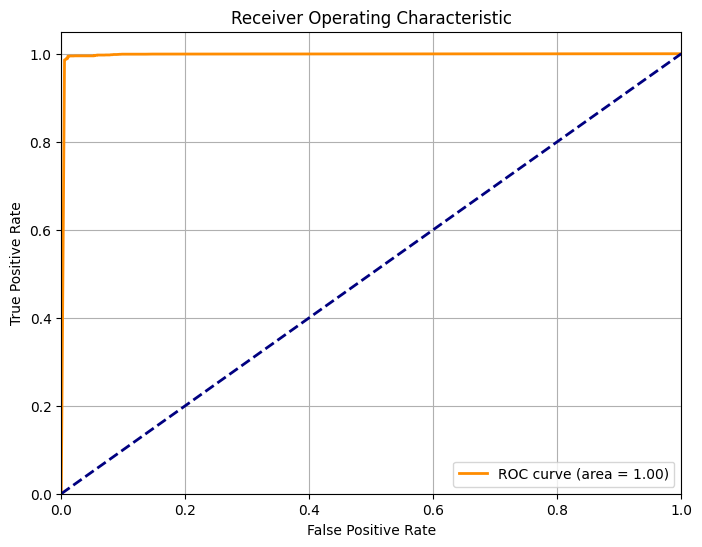

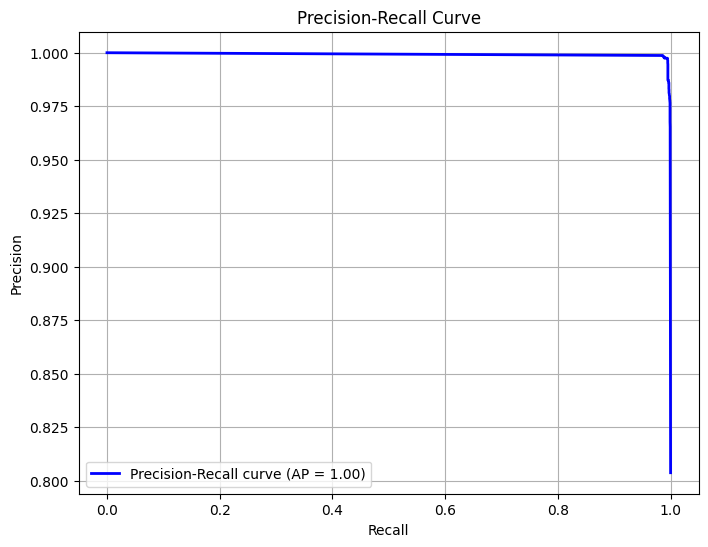

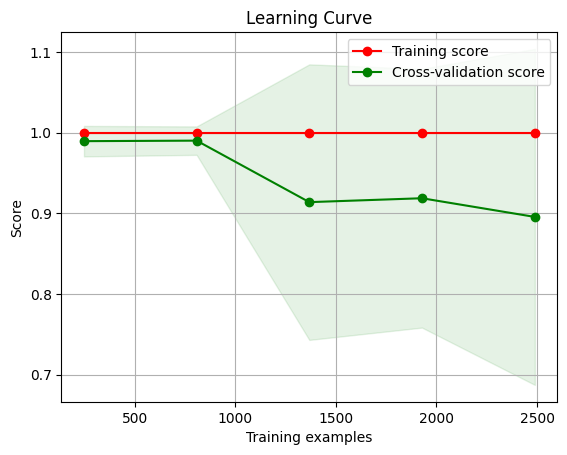

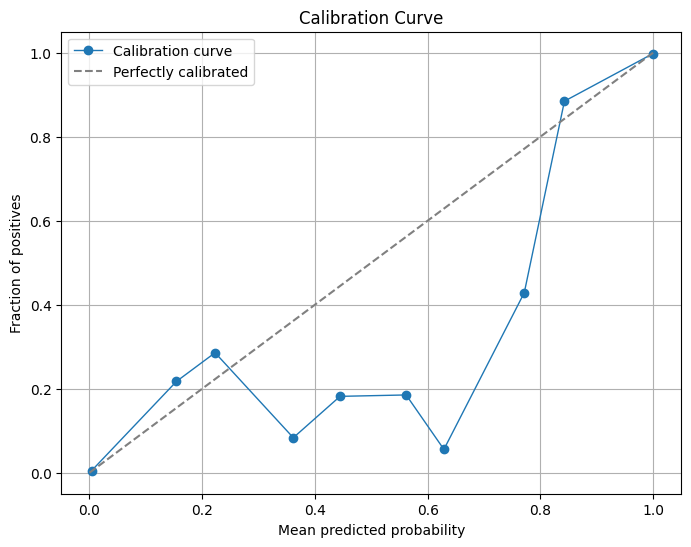

In [70]:
# 步骤1: 导入必要的库
import numpy as np
import pandas as pd
from tensorflow.keras.layers import Input, Dense
from tensorflow.keras.models import Model
from sklearn.metrics import accuracy_score, classification_report, roc_curve, auc, precision_recall_curve, average_precision_score
from sklearn.model_selection import train_test_split, learning_curve
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestClassifier
import warnings

warnings.filterwarnings("ignore")

# 步骤2: 定义自编码器模型
# 注意: 这里假设X_train_labelled和X_train_unlabelled已经被定义
input_dim = X_train_labelled.shape[1] #特征的数量
encoding_dim = 41#编码层的大小，数据在通过自编码器时压缩的程度

input_layer = Input(shape=(input_dim,))
encoded = Dense(encoding_dim, activation='relu')(input_layer)
decoded = Dense(input_dim, activation='sigmoid')(encoded)

autoencoder = Model(input_layer, decoded)
encoder = Model(input_layer, encoded)

autoencoder.compile(optimizer='adam', loss='binary_crossentropy')

# 步骤3: 使用未标记的数据训练自编码器
X_train_combined = pd.concat([X_train_labelled, X_train_unlabelled])
autoencoder.fit(X_train_combined, X_train_combined, epochs=50, batch_size=256, shuffle=True, validation_data=(X_test, X_test), verbose=0)

# 步骤4: 使用编码器提取特征
X_train_labelled_encoded = encoder.predict(X_train_labelled)
X_train_unlabelled_encoded = encoder.predict(X_train_unlabelled)
X_test_encoded = encoder.predict(X_test)

# 步骤5: 初始模型训练
clf = RandomForestClassifier(random_state=42)
clf.fit(X_train_labelled_encoded, y_train_labelled)

# 步骤6: 自训练迭代
max_iterations = 10
confidence_threshold = 0.9
low_confidence_sample_size = 100

for iteration in range(max_iterations):
    y_unlabelled_pred = clf.predict(X_train_unlabelled_encoded)
    y_unlabelled_proba = clf.predict_proba(X_train_unlabelled_encoded)
    
    high_confidence_indices = np.where(np.max(y_unlabelled_proba, axis=1) >= confidence_threshold)[0]
    
    if len(high_confidence_indices) == 0:
        break
    
    X_high_confidence = X_train_unlabelled_encoded[high_confidence_indices]
    y_high_confidence = y_unlabelled_pred[high_confidence_indices]
    
    X_train_labelled_encoded = np.concatenate([X_train_labelled_encoded, X_high_confidence])
    y_train_labelled = pd.concat([y_train_labelled, pd.Series(y_high_confidence)])
    
    X_train_unlabelled_encoded = np.delete(X_train_unlabelled_encoded, high_confidence_indices, axis=0)
    
    # 主动学习部分
    if len(X_train_unlabelled) < low_confidence_sample_size:
        low_confidence_sample_size = len(X_train_unlabelled)
    
    y_unlabelled_proba = clf.predict_proba(X_train_unlabelled)
    
    low_confidence_indices = np.argsort(np.max(y_unlabelled_proba, axis=1))[:low_confidence_sample_size]
    X_low_confidence = X_train_unlabelled.iloc[low_confidence_indices]
    
    # 重新计算低置信度样本的标签
    # 假设df_except是之前定义的包含所有可能标签的DataFrame
    X_low_confidence_features = X_low_confidence.reset_index(drop=True)
    y_low_confidence_labels = df_except[df_except.drop(columns=['label']).apply(tuple, axis=1).isin(X_low_confidence_features.apply(tuple, axis=1))]['label'].values
    
    if len(y_low_confidence_labels) < low_confidence_sample_size:
        print(f"Warning: Only found {len(y_low_confidence_labels)} labels for low confidence samples.")
        low_confidence_sample_size = len(y_low_confidence_labels)
        X_low_confidence = X_low_confidence.iloc[:low_confidence_sample_size]
    
    X_train_labelled = pd.concat([X_train_labelled, X_low_confidence])
    y_train_labelled = pd.concat([y_train_labelled, pd.Series(y_low_confidence_labels)])
    
    X_train_unlabelled = X_train_unlabelled.drop(X_low_confidence.index)
    #打印y_train_labelled长度和X_train_labelled_encoded长度
    print(f"y_train_labelled Length: {len(y_train_labelled)}")
    print(f"X_train_labelled_encoded Length: {len(X_train_labelled_encoded)}")
    clf.fit(X_train_labelled_encoded, y_train_labelled)

# 步骤7: 模型评估
y_pred = clf.predict(X_test_encoded)
y_pred_proba = clf.predict_proba(X_test_encoded)[:, 1]

print("Accuracy:", accuracy_score(y_test, y_pred))
print("Classification Report:")
print(classification_report(y_test, y_pred))

# 步骤8: 绘制ROC曲线和AUC
fpr, tpr, thresholds = roc_curve(y_test, y_pred_proba)
roc_auc = auc(fpr, tpr)

plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, color='darkorange', lw=2, label='ROC curve (area = %0.2f)' % roc_auc)
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic')
plt.legend(loc="lower right")
plt.grid(True)
plt.show()

# 步骤9: 绘制精确率-召回率曲线和平均精确率
precision, recall, _ = precision_recall_curve(y_test, y_pred_proba)
average_precision = average_precision_score(y_test, y_pred_proba)

plt.figure(figsize=(8, 6))
plt.plot(recall, precision, color='blue', lw=2, label='Precision-Recall curve (AP = %0.2f)' % average_precision)
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Precision-Recall Curve')
plt.legend(loc="lower left")
plt.grid(True)
plt.show()

# 步骤10: 绘制学习曲线
train_sizes, train_scores, test_scores = learning_curve(clf, X_train_labelled_encoded, y_train_labelled, n_jobs=-1, cv=5, train_sizes=np.linspace(.1, 1.0, 5), verbose=0)

train_scores_mean = np.mean(train_scores, axis=1)
train_scores_std = np.std(train_scores, axis=1)
test_scores_mean = np.mean(test_scores, axis=1)
test_scores_std = np.std(test_scores, axis=1)

plt.figure()
plt.title("Learning Curve")
plt.xlabel("Training examples")
plt.ylabel("Score")
plt.fill_between(train_sizes, train_scores_mean - train_scores_std, train_scores_mean + train_scores_std, alpha=0.1, color="r")
plt.fill_between(train_sizes, test_scores_mean - test_scores_std, test_scores_mean + test_scores_std, alpha=0.1, color="g")
plt.plot(train_sizes, train_scores_mean, 'o-', color="r", label="Training score")
plt.plot(train_sizes, test_scores_mean, 'o-', color="g", label="Cross-validation score")
plt.legend(loc="best")
plt.grid(True)
plt.show()

# 步骤11: 绘制校准曲线
prob_true, prob_pred = calibration_curve(y_test, y_pred_proba, n_bins=10)
plt.figure(figsize=(8, 6))
plt.plot(prob_pred, prob_true, marker='o', linewidth=1, label='Calibration curve')
plt.plot([0, 1], [0, 1], linestyle='--', color='gray', label='Perfectly calibrated')
plt.xlabel('Mean predicted probability')
plt.ylabel('Fraction of positives')
plt.title('Calibration Curve')
plt.legend()
plt.grid(True)
plt.show()